In [ ]:
! pip install -q pandas statsmodels matplotlib numpy matplotlib seaborn

## Question 3

Suppose we have a data set with five predictors:

- $X_1 =$ GPA
- $X_2 =$ IQ
- $X_3 =$ Level (1 for College and 0 for High School)
- $X_4 =$ Interaction between GPA and IQ
- $X_5 =$ Interaction between GPA and Level

The response is starting salary after graduation (in thousands of dollars).

Suppose we use least squares to fit the model, and get

$$
\hat{\beta}_0 = 50,\qquad
\hat{\beta}_1 = 20,\qquad
\hat{\beta}_2 = 0.07,\qquad
\hat{\beta}_3 = 35,\qquad
\hat{\beta}_4 = 0.01,\qquad
\hat{\beta}_5 = -10.
$$

### (a)

Which answer is correct, and why?

1. For a fixed value of IQ and GPA, high school graduates earn more, on average, than college graduates.

2. For a fixed value of IQ and GPA, college graduates earn more, on average, than high school graduates.

3. For a fixed value of IQ and GPA, high school graduates earn more, on average, than college graduates provided that the GPA is high enough.

4. For a fixed value of IQ and GPA, college graduates earn more, on average, than high school graduates provided that the GPA is high enough.

### (b)

Predict the salary of a college graduate with IQ of 110 and a GPA of 4.0.

### (c)

True or false:

Since the coefficient for the GPA/IQ interaction term is very small, there is very little evidence of an interaction effect.

Justify your answer.

### (a) 解答

題目的迴歸模型為

$$
Y
=
\beta_0
+\beta_1(\text{GPA})
+\beta_2(\text{IQ})
+\beta_3(\text{Level})
+\beta_4(\text{GPA}\times\text{IQ})
+\beta_5(\text{GPA}\times\text{Level})
+\epsilon.
$$

預測模型為

$$
\hat{Y}
=
50
+20(\text{GPA})
+0.07(\text{IQ})
+35(\text{Level})
+0.01(\text{GPA})(\text{IQ})
-10(\text{GPA})(\text{Level}).
$$

其中

$$
\text{Level}
=
\begin{cases}
1, & \text{College},\\
0, & \text{High School}.
\end{cases}
$$

當學生為 High School graduate 時，$\text{Level}=0$，所以

$$
\hat{Y}_{HS}
=
50
+20(\text{GPA})
+0.07(\text{IQ})
+0.01(\text{GPA})(\text{IQ}).
$$

當學生為 College graduate 時，$\text{Level}=1$，所以

$$
\hat{Y}_{C}
=
50
+20(\text{GPA})
+0.07(\text{IQ})
+35
+0.01(\text{GPA})(\text{IQ})
-10(\text{GPA}).
$$

因此 College 與 High School 的預測薪資差為

$$
\hat{Y}_{C}-\hat{Y}_{HS}
=
35-10(\text{GPA}).
$$

當

$$
35-10(\text{GPA})<0
$$

時，High School graduates 的預測薪資較高。

解得

$$
\boxed{\text{GPA}>3.5}.
$$

因此，當 GPA 大於 3.5 時，High School graduates 的平均預測薪資會高於 College graduates。



### (b) 解答

題目的迴歸模型為

$$
\hat{Y}
=
50
+20(\text{GPA})
+0.07(\text{IQ})
+35(\text{Level})
+0.01(\text{GPA})(\text{IQ})
-10(\text{GPA})(\text{Level}).
$$

已知

$$
\text{GPA}=4.0,\qquad \text{IQ}=110,\text{Level}=1.
$$

代入模型：

$$
\begin{aligned}
\hat{Y}
&=
50
+20(4)
+0.07(110)
+35(1)
+0.01(4)(110)
-10(4)(1)\\
&=
50+80+7.7+35+4.4-40\\
&=
137.1.
\end{aligned}
$$

由於薪資的單位是千美元，因此預測的起薪為

$$
\boxed{137,100\text{ 美元}}.
$$

### (c) 解答

雖然 GPA 與 IQ 的交互作用項係數為

$$
\hat{\beta}_4=0.01,
$$

但不能只根據係數的數值大小來判斷是否存在交互作用。

交互作用項在模型中為

$$
0.01(\text{GPA})(\text{IQ}).
$$

由於 GPA 與 IQ 會相乘，因此即使係數為 $0.01$，實際對預測值的影響仍可能不小。

例如，若

$$
\text{GPA}=4,\qquad \text{IQ}=110,
$$

則交互作用項的貢獻為

$$
0.01(4)(110)=4.4.
$$

因此，係數的大小本身不能用來判斷交互作用是否具有統計上的證據。

若要判斷 GPA 與 IQ 的交互作用是否顯著，應該檢查該係數的標準誤、t 統計量或 p-value，例如檢定

$$
H_0:\beta_4=0.
$$

因此敘述為

$$
\boxed{\text{False}}
$$

## Question 4

I collect a set of data ($n=100$ observations) containing a single predictor and a quantitative response.

I then fit a linear regression model to the data, as well as a separate cubic regression, i.e.

$$
Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \epsilon.
$$

### (a)

Suppose that the true relationship between $X$ and $Y$ is linear, i.e.

$$
Y = \beta_0 + \beta_1X + \epsilon.
$$

Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression.

Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell?

Justify your answer.

### (b)

Answer (a) using **test** rather than training RSS.

### (c)

Suppose that the true relationship between $X$ and $Y$ is not linear, but we don't know how far it is from linear.

Consider the training RSS for the linear regression, and also the training RSS for the cubic regression.

Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell?

Justify your answer.

### (d)

Answer (c) using **test** rather than training RSS.

### (a) 解答

真實模型為

$$
Y=\beta_0+\beta_1X+\epsilon.
$$

我們比較兩個模型：

線性模型：

$$
Y=\beta_0+\beta_1X+\epsilon
$$

以及三次模型：

$$
Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon.
$$

三次模型包含線性模型作為特殊情況，因為只要令

$$
\beta_2=0,\qquad \beta_3=0,
$$

三次模型就會變成線性模型。

由於最小平方法會選擇使 training RSS 最小的係數，而三次模型具有更多參數與更大的模型空間，因此它至少可以達到和線性模型一樣小的 RSS。

因此

$$
\boxed{
RSS_{\text{cubic}}
\leq
RSS_{\text{linear}}
}
$$

$$
\boxed{\text{三次模型的 training RSS 會小於或等於線性模型}}
$$

### (b) 解答

題目已知真實關係為線性：

$$
Y=\beta_0+\beta_1X+\epsilon.
$$

因此線性模型的形式與真實資料產生機制一致。

雖然三次模型

$$
Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon
$$

在 training data 上可以利用額外的 $X^2$ 與 $X^3$ 降低 RSS，但這些額外項目在真實模型中並不存在，因此可能只是對 training data 中的雜訊進行配適。

這可能會產生 overfitting。

因此在 test data 上，我們理論上預期線性模型具有較小的 test RSS：

$$
\boxed{
RSS_{\text{linear,test}}
<
RSS_{\text{cubic,test}}
}
$$
$$
\boxed{\text{三次模型的 test RSS 會大於或等於線性模型}}
$$

### (c) 解答

若 $X$ 與 $Y$ 的真實關係不是線性的。

比較線性模型

$$
Y=\beta_0+\beta_1X+\epsilon
$$

以及三次模型

$$
Y=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon.
$$

三次模型包含線性模型作為特殊情況，因為只要令

$$
\beta_2=0,\qquad \beta_3=0,
$$

三次模型就會退化成線性模型。

因此，三次模型具有更大的模型空間與更多自由度，可以至少做到和線性模型一樣好的 training data 配適。

所以一定有

$$
RSS_{\text{cubic,train}}
\leq
RSS_{\text{linear,train}}.
$$

此外，題目已知真實關係不是線性的，因此三次模型中的 $X^2$ 與 $X^3$ 項可能可以捕捉部分非線性關係。

因此通常預期

$$
\boxed{
RSS_{\text{cubic,train}}
<
RSS_{\text{linear,train}}
}
$$

$$
\boxed{\text{三次模型的 training RSS 會小於或等於線性模型}}
$$

### (d) 解答

題目說 $X$ 與 $Y$ 的真實關係不是線性的，但不知道這個非線性關係有多強。

在 test data 上，比較線性模型與三次模型時，不能只看模型複雜度，還需要考慮 bias 與 variance 之間的取捨。

如果真實關係只有輕微的非線性，線性模型雖然有一些 bias，但模型較簡單、variance 較小，因此可能有較小的 test RSS。

另一方面，如果真實關係具有明顯的非線性，而且三次模型能有效捕捉這種關係，那麼三次模型可能有較小的 test RSS。

因此，題目給的非線性條件太模糊了，無法確定哪一個模型的 test RSS 較小。

所以答案為：

$$
\boxed{\text{沒有足夠資訊判斷哪一個 test RSS 較小}}
$$

## Question 10

This question should be answered using the **Carseats** data set.

### (a)

Fit a multiple regression model to predict `Sales` using `Price`, `Urban`, and `US`.

### (b)

Provide an interpretation of each coefficient in the model. Be careful — some of the variables in the model are qualitative!

### (c)

Write out the model in equation form, being careful to handle the qualitative variables properly.

### (d)

For which of the predictors can you reject the null hypothesis

$$
H_0:\beta_j = 0?
$$

### (e)

On the basis of your response to the previous question, fit a smaller model that only uses the predictors for which there is evidence of association with the outcome.

### (f)

How well do the models in (a) and (e) fit the data?

### (g)

Using the model from (e), obtain 95% confidence intervals for the coefficient(s).

### (h)

Is there evidence of outliers or high leverage observations in the model from (e)?

### (a) 解答

以 `Sales` 作為反應變數，並使用 `Price`、`Urban` 與 `US` 作為解釋變數，建立多元線性迴歸模型：

$$
Sales
=
\beta_0
+\beta_1 Price
+\beta_2 Urban
+\beta_3 US
+\epsilon.
$$

其中 `Urban` 與 `US` 為類別變數，以 `No` 作為基準組。

配適後得到的迴歸模型約為

$$
\widehat{Sales}
=
13.0435
-0.0545(Price)
-0.0219(Urban_{Yes})
+1.2006(US_{Yes}).
$$

其中：

- `Price` 的估計係數約為 $-0.0545$。
- `UrbanYes` 的估計係數約為 $-0.0219$。
- `USYes` 的估計係數約為 $1.2006$。

因此，此模型使用商品價格、是否位於都市以及是否位於美國，來預測 `Sales`。

In [6]:
import statsmodels.formula.api as smf
import pandas as pd

Carseats = pd.read_csv("./data/Carseats.csv")

model_10a = smf.ols(
    "Sales ~ Price + C(Urban) + C(US)",
    data=Carseats
).fit()

print(model_10a.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.234
Method:                 Least Squares   F-statistic:                     41.52
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           2.39e-23
Time:                        11:24:27   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1863.
Df Residuals:                     396   BIC:                             1879.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          13.0435      0.651     

### (b) 解答

10(a) 得到的迴歸模型約為

$$
\widehat{Sales}
=
13.0435
-0.0545(Price)
-0.0219(Urban_{Yes})
+1.2006(US_{Yes}).
$$

其中 `Urban` 與 `US` 為類別變數，並以 `No` 作為基準組。

#### 截距

截距為

$$
13.0435.
$$

代表當

$$
Price=0,\qquad Urban=No,\qquad US=No
$$

時，預測的 `Sales` 為 13.0435。

不過由於 `Price=0` 在實際資料中可能沒有實際意義，因此截距主要可視為模型中的基準值。

#### Price

`Price` 的係數為

$$
-0.0545.
$$

在 `Urban` 與 `US` 固定的情況下，`Price` 每增加 1 單位，預測的 `Sales` 平均減少約

$$
0.0545.
$$

也就是說，價格越高，銷售量通常越低。

#### Urban

`UrbanYes` 的係數為

$$
-0.0219.
$$

在 `Price` 與 `US` 固定的情況下，都市地區的店家相比非都市地區的店家，預測的 `Sales` 平均低約

$$
0.0219.
$$

由於這個差異非常小，因此都市與非都市地區在銷售量上的差異看起來不明顯。

#### US

`USYes` 的係數為

$$
1.2006.
$$

在 `Price` 與 `Urban` 固定的情況下，位於美國的店家相比非美國店家，預測的 `Sales` 平均高約

$$
1.2006.
$$

因此，是否位於美國與 `Sales` 有較明顯的正向關係。

### (c) 解答

由 10(a) 得到的模型為

$$
\widehat{Sales}
=
13.0435
-0.0545(Price)
-0.0219(Urban_{Yes})
+1.2006(US_{Yes}).
$$

其中定義虛擬變數

$$
Urban_{Yes}
=
\begin{cases}
1, & \text{若 Urban = Yes}\\
0, & \text{若 Urban = No}
\end{cases}
$$

以及

$$
US_{Yes}
=
\begin{cases}
1, & \text{若 US = Yes}\\
0, & \text{若 US = No}
\end{cases}.
$$

因此完整模型可寫為

$$
\boxed{
\widehat{Sales}
=
13.043
-0.0545(Price)
-0.0219I(Urban=Yes)
+1.2006I(US=Yes)
}
$$

因此：

- 若 `Urban = No`，則都市項為 0。
- 若 `Urban = Yes`，則都市項為 $-0.0219$。
- 若 `US = No`，則美國項為 0。
- 若 `US = Yes`，則美國項為 $1.2006$。

### (d) 解答

我們對每一個 predictor 檢定

$$
H_0:\beta_j=0
$$

並使用顯著水準

$$
\alpha=0.05.
$$

當

$$
p<0.05
\Rightarrow
\text{reject }H_0,
$$

表示該 predictor 與 `Sales` 之間具有統計上顯著的關聯。

反之，

$$
p\geq0.05
\Rightarrow
\text{do not reject}H_0.
$$

其中，`Urban` 的 p-value 為

$$
p=0.936>0.05,
$$

因此無法拒絕

$$
H_0:\beta_{Urban}=0.
$$

表示在控制 `Price` 與 `US` 後，沒有足夠證據認為 `Urban` 與 `Sales` 有顯著關聯。

`US` 的 p-value 小於 $0.001$：

$$
p<0.001<0.05,
$$

因此拒絕

$$
H_0:\beta_{US}=0.
$$

表示在控制其他變數後，`US` 與 `Sales` 具有顯著關聯。

`Price` 的 p-value 也小於 $0.001$：

$$
p<0.001<0.05,
$$

因此拒絕

$$
H_0:\beta_{Price}=0.
$$

表示在控制其他變數後，`Price` 與 `Sales` 具有顯著關聯。

因此，在 $\alpha=0.05$ 的顯著水準下，可以拒絕虛無假設的 predictors 為

$$
\boxed{US \text{ 與 } Price}
$$

而 `Urban` 不顯著。

### (e) 解答

根據 10(d) 的結果將不顯著的 `Urban` 從模型中移除，只保留 `US` 與 `Price`，重新建立較精簡的模型：

$$
Sales
=
\beta_0
+\beta_1 I(US=Yes)
+\beta_2 Price
+\epsilon.
$$

重新配適後得到：

$$
\boxed{
\widehat{Sales}
=
13.0308
+1.1996I(US=Yes)
-0.0545Price
}
$$

其中

$$
I(US=Yes)
=
\begin{cases}
1, & \text{若 US = Yes}\\
0, & \text{若 US = No}
\end{cases}
$$

在這個較小的模型中：

- `US` 的 p-value 小於 $0.001$，仍然顯著。
- `Price` 的 p-value 小於 $0.001$，仍然顯著。

因此，最終的 reduced model 為

$$
\boxed{
Sales \sim Price + US
}
$$

也就是說，刪除不顯著的 `Urban` 後，只使用 `Price` 與 `US` 來預測 `Sales`。

In [5]:
model_10e = smf.ols(
    "Sales ~ Price + C(US)",
    data=Carseats
).fit()

print(model_10e.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     62.43
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           2.66e-24
Time:                        11:24:15   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1861.
Df Residuals:                     397   BIC:                             1873.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       13.0308      0.631     20.652   

### (f) 解答

比較 10(a) 的完整模型

$$
Sales \sim Price + Urban + US
$$

與 10(e) 的精簡模型

$$
Sales \sim Price + US.
$$

兩個模型的 $R^2$, adjusted $R^2$, AIC, BIC 分別為：

| Model | $R^2$ | Adjusted $R^2$ | AIC | BIC |
|---|---:|---:|---:|---:|
| 完整模型 | 0.239 | 0.234 | 1863 | 1879 |
| 精簡模型 | 0.239 | 0.235 | 1861 | 1873 |

兩個模型的 $R^2$ 幾乎相同，表示移除 `Urban` 後，模型對 `Sales` 的解釋能力幾乎沒有改變。

此外，精簡模型的 adjusted $R^2$ 稍微高於完整模型：

$$
0.235>0.234.
$$

這表示在考慮模型中 predictor 數量之後，刪除不顯著的 `Urban` 並沒有降低模型的整體配適效果。

而精簡模型的 AIC 與 BIC 都較小，因此在考慮模型複雜度後，精簡模型較為簡潔且配適效果幾乎沒有損失。

另外，兩個模型的 $R^2$ 都約為

$$
0.239,
$$

表示模型大約只能解釋 `Sales` 變異的

$$
23.9\%.
$$

因此，這兩個模型對資料的整體解釋能力都不算高，但移除 `Urban` 後並沒有明顯降低模型的配適程度。

### (g) 解答

使用 10(e) 的精簡模型

$$
Sales \sim Price + US
$$

求各迴歸係數的 95% 信賴區間。

根據模型輸出，各係數的 95% confidence interval 為：

| 係數 | 95% 信賴區間 |
|---|---|
| Intercept | $(11.790,\ 14.271)$ |
| `USYes` | $(0.692,\ 1.708)$ |
| `Price` | $(-0.065,\ -0.044)$ |

因此，

$$
\beta_0 \in (11.790,\ 14.271),
$$

$$
\beta_{US} \in (0.692,\ 1.708),
$$

以及

$$
\beta_{Price} \in (-0.065,\ -0.044).
$$

其中，`US` 的 95% 信賴區間完全大於 0：

$$
(0.692,\ 1.708),
$$

表示在控制 `Price` 後，位於美國的店家相較於非美國店家，其平均 `Sales` 較高。

`Price` 的 95% 信賴區間則完全小於 0：

$$
(-0.065,\ -0.044),
$$

表示在控制 `US` 後，`Price` 與 `Sales` 之間具有負向關係。

另外，`US` 與 `Price` 的 95% 信賴區間皆不包含 0，因此這也與前面的假設檢定結果一致，兩者皆具有統計上的顯著性。

In [9]:
ci = model_10e.conf_int(alpha=0.05)
ci.columns = ["2.5%", "97.5%"]
display(ci)


,2.5%,97.5%
Intercept,11.79032,14.271265
C(US)[T.Yes],0.69152,1.707766
Price,-0.06476,-0.044195


### (h) 解答

使用模型

$$
Sales \sim Price + US
$$

檢查是否存在 outliers 或 high leverage observations。

#### Outlier

可以使用 studentized residual 判斷離群點。

一般而言，如果

$$
|r_i|>3,
$$

則該 observation 可能被視為明顯的 outlier。

由診斷結果可發現，所有 studentized residual 大致都落在

$$
-3<r_i<3
$$

的範圍內。

因此，沒有明顯證據顯示資料中存在嚴重的 outlier。

#### High Leverage Observation

leverage 的平均值為

$$
\bar{h}=\frac{p+1}{n},
$$

其中模型包含兩個 predictors：`Price` 與 `US`，因此

$$
p=2,
\qquad
n=400.
$$

所以平均 leverage 為

$$
\bar{h}
=
\frac{2+1}{400}
=
0.0075.
$$

如果某些 observation 的 leverage 明顯高於平均值，例如

$$
h_i>2\bar{h},
$$

則可以視為 high leverage observations。

從模型的 leverage 診斷結果可以發現，20 個 observations 的 leverage 高於 $2\bar{h},$

因此，本模型：

$$
\boxed{\text{沒有明顯的 outliers，但存在一些 high leverage observations}}
$$

In [ ]:
import numpy as np
import statsmodels.api as sm

influence = model_10e.get_influence()

# Studentized residuals
studentized_resid = influence.resid_studentized_external

# Leverage
leverage = influence.hat_matrix_diag

n = Carseats.shape[0]
p = 2   # Price 和 US 兩個 predictor

print("最大絕對 studentized residual:",
      np.max(np.abs(studentized_resid)))

print("平均 leverage:",
      (p + 1) / n)

print("Studentized residual > 3 的數量:",
      np.sum(np.abs(studentized_resid) > 3))

print("Leverage > 2*(p+1)/n 的數量:",
      np.sum(leverage > 2 * (p + 1) / n))

最大絕對 studentized residual: 2.8915213186304483
平均 leverage: 0.0075
Studentized residual > 3 的數量: 0
Leverage > 2*(p+1)/n 的數量: 20


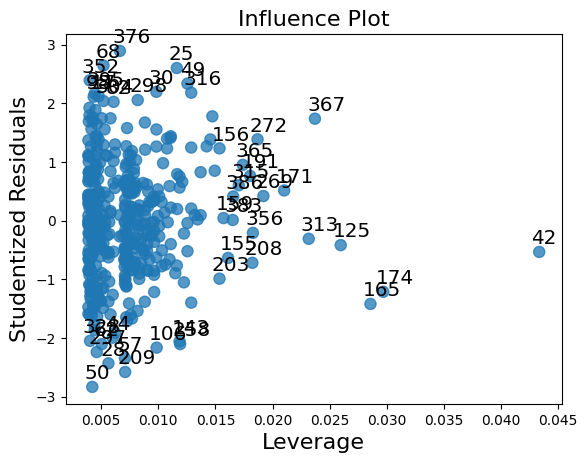

In [ ]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

sm.graphics.influence_plot(
    model_10e,
    criterion="cooks",
    size=8
)

plt.show()

## Question 15

This problem involves the **Boston** data set, which we saw in the lab for this chapter. We will now try to predict per capita crime rate using the other variables in this data set. In other words, per capita crime rate is the response, and the other variables are the predictors.

### (a)

For each predictor, fit a simple linear regression model to predict the response. Describe your results.

In which of the models is there a statistically significant association between the predictor and the response?

Create some plots to back up your assertions.

### (b)

Fit a multiple regression model to predict the response using all of the predictors. Describe your results.

For which predictors can we reject the null hypothesis

$$
H_0:\beta_j = 0?
$$

### (c)

How do your results from (a) compare to your results from (b)?

Create a plot displaying the univariate regression coefficients from (a) on the x-axis, and the multiple regression coefficients from (b) on the y-axis.

That is, each predictor is displayed as a single point in the plot. Its coefficient in a simple linear regression model is shown on the x-axis, and its coefficient estimate in the multiple linear regression model is shown on the y-axis.

### (d)

Is there evidence of non-linear association between any of the predictors and the response?

To answer this question, for each predictor $X$, fit a model of the form

$$
Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \epsilon.
$$

### (a) 解答

本題將 `crim` 作為反應變數，並分別對其他每一個 predictor 建立簡單線性迴歸模型：

$$
crim=\beta_0+\beta_1X+\epsilon.
$$

對每一個 predictor 檢定：

$$
H_0:\beta_1=0
$$

並使用顯著水準

$$
\alpha=0.05.
$$

若 $p<0.05$，則拒絕 $H_0$，表示該 predictor 與 `crim` 具有顯著的線性關聯。

根據迴歸結果：

| Predictor | Coefficient | p-value | $R^2$ | 結果 |
|---|---:|---:|---:|---|
| `zn` | -0.0739 | $5.51\times10^{-6}$ | 0.040 | 顯著負向 |
| `indus` | 0.5098 | $1.45\times10^{-21}$ | 0.165 | 顯著正向 |
| `chas` | -1.8928 | 0.209 | 0.003 | 不顯著 |
| `nox` | 31.2485 | $3.75\times10^{-23}$ | 0.177 | 顯著正向 |
| `rm` | -2.6841 | $6.35\times10^{-7}$ | 0.048 | 顯著負向 |
| `age` | 0.1078 | $2.85\times10^{-16}$ | 0.124 | 顯著正向 |
| `dis` | -1.5509 | $8.52\times10^{-19}$ | 0.144 | 顯著負向 |
| `rad` | 0.6179 | $2.69\times10^{-56}$ | 0.391 | 顯著正向 |
| `tax` | 0.0297 | $2.36\times10^{-47}$ | 0.340 | 顯著正向 |
| `ptratio` | 1.1520 | $2.94\times10^{-11}$ | 0.084 | 顯著正向 |
| `lstat` | 0.5488 | $2.65\times10^{-27}$ | 0.208 | 顯著正向 |
| `medv` | -0.3632 | $1.17\times10^{-19}$ | 0.151 | 顯著負向 |

因此，在 $\alpha=0.05$ 下，

$$
\boxed{\text{除了 chas 之外，其餘 predictors 均與 crim 有顯著的線性關聯。}}
$$

其中：

- 與 `crim` 呈顯著負向關係的變數為

$$
\boxed{zn,\ rm,\ dis,\ medv}
$$

- 與 `crim` 呈顯著正向關係的變數為

$$
\boxed{indus,\ nox,\ age,\ rad,\ tax,\ ptratio,\ lstat}
$$

- `chas` 的 p-value 為

$$
p=0.209>0.05,
$$

因此無法拒絕 $H_0$，沒有足夠證據認為 `chas` 與 `crim` 存在顯著線性關聯。

從散佈圖與迴歸線也可以觀察到相同的方向。例如 `rad`、`tax` 與 `lstat` 隨數值增加時，`crim` 整體呈上升趨勢；而 `dis`、`rm` 與 `medv` 則呈下降趨勢。

其中 `rad` 的

$$
R^2=0.391
$$

為所有單變量模型中最高，其次為 `tax` 的

$$
R^2=0.340.
$$

這表示在單獨使用一個 predictor 的情況下，`rad` 與 `tax` 對 `crim` 的線性解釋能力相對較高。

此外，部分散佈圖如 `dis` 與 `nox` 呈現一定程度的曲線型態，因此 predictor 與 `crim` 之間可能不完全是線性關係，後續可再進一步檢查非線性效果。

In [22]:
# response
Boston = pd.read_csv("./data/Boston.csv")
Boston = Boston.drop(columns=["Unnamed: 0"], errors="ignore")
response = "crim"

# 除了 crim 以外的所有 predictor
predictors = [col for col in Boston.columns if col != response]

results = []

for x in predictors:
    X = sm.add_constant(Boston[[x]])
    y = Boston[response]

    model = sm.OLS(y, X).fit()

    results.append({
        "Predictor": x,
        "Coefficient": model.params[x],
        "P-value": model.pvalues[x],
        "R-squared": model.rsquared
    })

results_df = pd.DataFrame(results)
display(results_df)

results_df["Significant"] = results_df["P-value"] < 0.05
display(results_df)

,Predictor,Coefficient,P-value,R-squared
0,zn,-0.073935,5.506472e-06,0.040188
1,indus,0.509776,1.450349e-21,0.165310
2,chas,-1.892777,2.094345e-01,0.003124
3,nox,31.248531,3.751739e-23,0.177217
4,rm,-2.684051,6.346703e-07,0.048069
5,age,0.107786,2.854869e-16,0.124421
6,dis,-1.550902,8.519949e-19,0.144149
7,rad,0.617911,2.693844e-56,0.391257
8,tax,0.029742,2.357127e-47,0.339614
9,ptratio,1.151983,2.942922e-11,0.084068


,Predictor,Coefficient,P-value,R-squared,Significant
0,zn,-0.073935,5.506472e-06,0.040188,True
1,indus,0.509776,1.450349e-21,0.165310,True
2,chas,-1.892777,2.094345e-01,0.003124,False
3,nox,31.248531,3.751739e-23,0.177217,True
4,rm,-2.684051,6.346703e-07,0.048069,True
5,age,0.107786,2.854869e-16,0.124421,True
6,dis,-1.550902,8.519949e-19,0.144149,True
7,rad,0.617911,2.693844e-56,0.391257,True
8,tax,0.029742,2.357127e-47,0.339614,True
9,ptratio,1.151983,2.942922e-11,0.084068,True


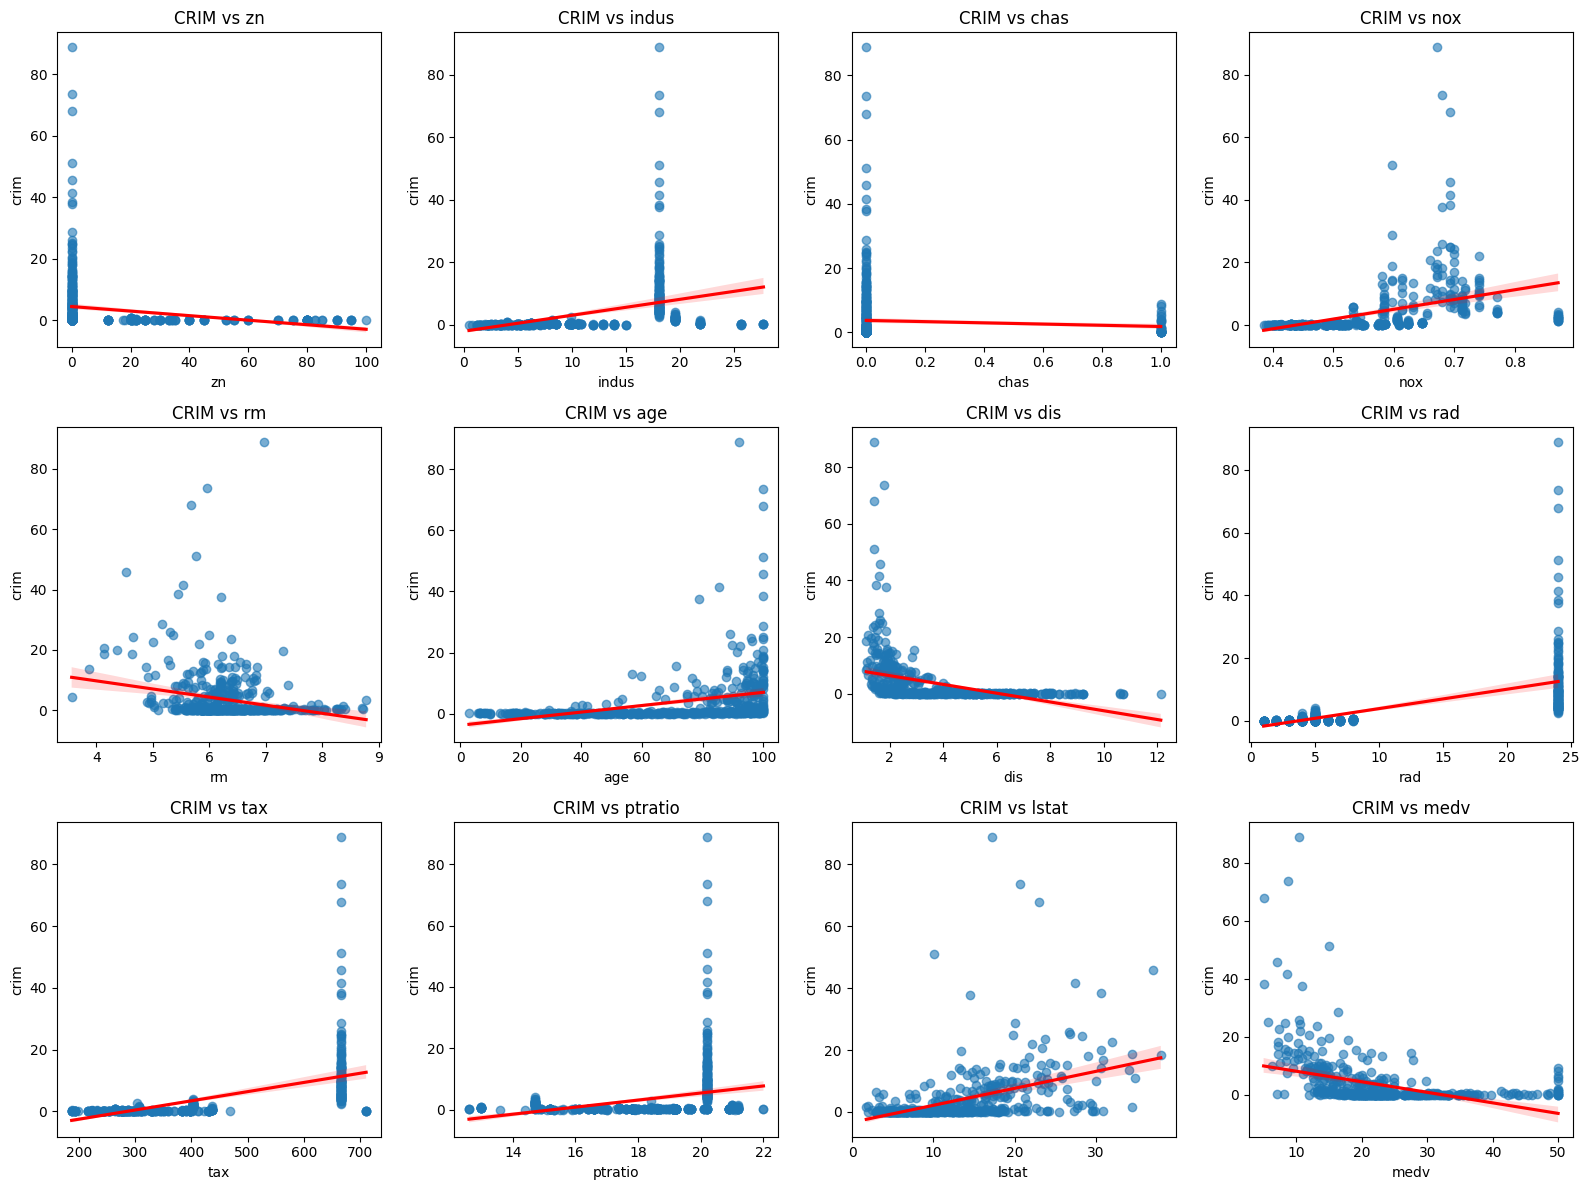

In [26]:
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

axes = axes.flatten()

for i, x in enumerate(predictors):
    sns.regplot(
        data=Boston,
        x=x,
        y="crim",
        ax=axes[i],
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"}
    )

    axes[i].set_title(f"CRIM vs {x}")
    axes[i].set_xlabel(x)
    axes[i].set_ylabel("crim")
    
plt.tight_layout()
plt.show()

### (b) 解答

本題以 `crim` 作為反應變數，並將其餘 12 個 predictors 同時放入多元線性迴歸模型：

$$
crim
=
\beta_0+\beta_1X_1+\beta_2X_2+\cdots+\beta_{12}X_{12}+\epsilon.
$$

對每一個 predictor 檢定：

$$
H_0:\beta_j=0
$$

並使用顯著水準

$$
\alpha=0.05.
$$

若 $p<0.05$ 則拒絕 $H_0$，表示在控制其他 predictors 後，該 predictor 與 `crim` 仍具有顯著關聯。

根據多元線性迴歸結果：

| Predictor | Coefficient | p-value | 判斷 |
|---|---:|---:|---|
| `zn` | 0.0457 | 0.015 | 顯著 |
| `indus` | -0.0584 | 0.486 | 不顯著 |
| `chas` | -0.8254 | 0.486 | 不顯著 |
| `nox` | -9.9576 | 0.060 | 不顯著 |
| `rm` | 0.6289 | 0.301 | 不顯著 |
| `age` | -0.0008 | 0.962 | 不顯著 |
| `dis` | -1.0122 | $<0.001$ | 顯著 |
| `rad` | 0.6125 | $<0.001$ | 顯著 |
| `tax` | -0.0038 | 0.466 | 不顯著 |
| `ptratio` | -0.3041 | 0.103 | 不顯著 |
| `lstat` | 0.1388 | 0.067 | 不顯著 |
| `medv` | -0.2201 | $<0.001$ | 顯著 |

因此，在 $\alpha=0.05$ 下，可以拒絕

$$
H_0:\beta_j=0
$$

的 predictors 為

$$
\boxed{zn,\ dis,\ rad,\ medv}.
$$

其中：

- `zn` 的係數為正，表示在控制其他變數後，`zn` 與 `crim` 呈顯著正向關係。
- `dis` 的係數為負，表示 `dis` 與 `crim` 呈顯著負向關係。
- `rad` 的係數為正，表示 `rad` 與 `crim` 呈顯著正向關係。
- `medv` 的係數為負，表示 `medv` 與 `crim` 呈顯著負向關係。

另外，`nox` 與 `lstat` 的 p-value 分別為

$$
0.060\quad\text{與}\quad0.067,
$$

雖然接近 $0.05$，但仍然大於顯著水準，因此不能拒絕其虛無假設。

整體模型的

$$
R^2=0.449,
\qquad
Adjusted\ R^2=0.436.
$$

表示所有 predictors 同時放入模型後，可以解釋約 $44.9\%$ 的 `crim` 變異。

此外，整體 F 檢定的 p-value 為

$$
2.03\times10^{-56},
$$

遠小於 $0.05$，因此整體迴歸模型具有統計上的顯著性。

值得注意的是，許多在 15(a) 的簡單線性迴歸中顯著的 predictors，在多元迴歸中變得不顯著。這表示這些 predictors 之間可能共享部分解釋資訊；在控制其他變數之後，部分變數已無法提供顯著的額外解釋能力。

In [27]:
# response
y = Boston["crim"]

# 所有其他 predictor
predictors = [col for col in Boston.columns if col != "crim"]

X = Boston[predictors]
X = sm.add_constant(X)

model_15b = sm.OLS(y, X).fit()

print(model_15b.summary())

                            OLS Regression Results                            
Dep. Variable:                   crim   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.436
Method:                 Least Squares   F-statistic:                     33.52
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           2.03e-56
Time:                        14:01:33   Log-Likelihood:                -1655.4
No. Observations:                 506   AIC:                             3337.
Df Residuals:                     493   BIC:                             3392.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.7784      7.082      1.946      0.0

### (c) 解答

15(a) 的 simple linear regression 一次只使用一個 predictor，而 15(b) 的 multiple regression 則將所有 predictors 同時放入模型。

在 15(a) 中，除了 `chas` 外，其餘 predictors 幾乎都與 `crim` 顯著相關；但在 15(b) 中，控制其他 predictors 後，在 $\alpha=0.05$ 下只剩

$$
\boxed{zn,\ dis,\ rad,\ medv}
$$

仍具有顯著關聯。

此外，部分 predictor 的 coefficient 不只大小改變，甚至發生正負方向反轉，例如：

$$
zn:\ -0.0739\rightarrow0.0457,
$$

$$
indus:\ 0.5098\rightarrow-0.0584,
$$

$$
nox:\ 31.2485\rightarrow-9.9576,
$$

$$
rm:\ -2.6841\rightarrow0.6289.
$$

這表示 simple regression 中觀察到的關係，可能同時受到其他 predictors 的影響；在 multiple regression 中，每個係數則表示控制其他變數後，該 predictor 與 `crim` 的獨立線性關係。

在係數比較圖中，每個 predictor 對應

$$
(\hat{\beta}_{simple},\hat{\beta}_{multiple}).
$$

虛線 $y=x$ 表示兩種模型的 coefficient 相同，因此點越接近 $y=x$，代表加入其他 predictors 後係數變化越小。

從圖中可看出：

- `nox` 距離 $y=x$ 最遠，而且由正值變成負值，表示其 coefficient 受到其他 predictors 的影響最明顯。
- `zn`、`indus`、`rm` 等也出現正負方向反轉。
- `rad` 的點相當接近 $y=x$，表示其 coefficient 在 simple 與 multiple regression 中相對穩定。
- 大多數點集中在原點附近，而 `nox` 的 coefficient 特別大，因此拉大了整張圖的尺度。

整體而言，

$$
\boxed{\text{simple regression 與 multiple regression 的結果有明顯差異}}
$$

表示 predictors 彼此之間存在相關性，因此單獨分析某個 predictor 與控制其他 predictors 後得到的效果可能不同。

,Simple,Multiple
zn,-0.073935,0.045710
indus,0.509776,-0.058350
chas,-1.892777,-0.825378
nox,31.248531,-9.957587
rm,-2.684051,0.628911
age,0.107786,-0.000848
dis,-1.550902,-1.012247
rad,0.617911,0.612465
tax,0.029742,-0.003776
ptratio,1.151983,-0.304073


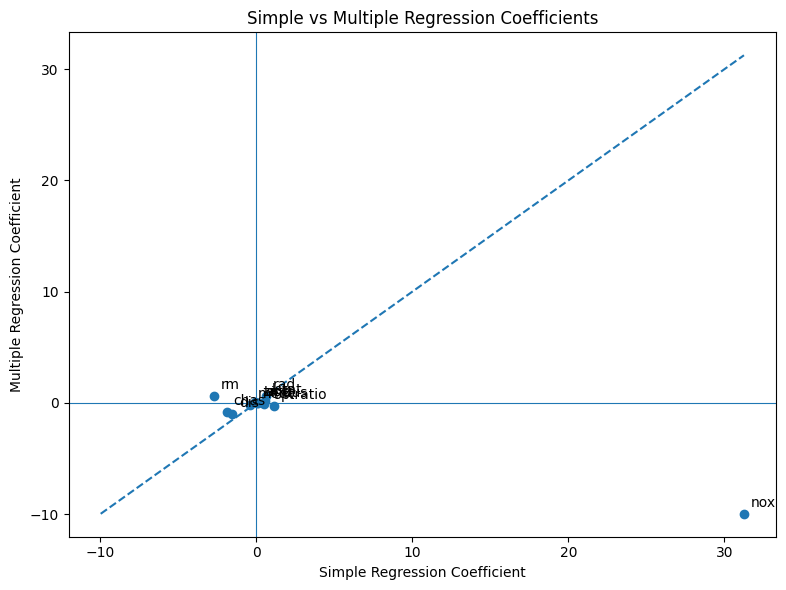

In [29]:
# 15(a) 的 模型
simple_coef = (
    results_df
    .set_index("Predictor")["Coefficient"]
)

# 15(b) 的 模型
multiple_coef = model_15b.params.drop("const")

# 合併
coef_compare = pd.DataFrame({
    "Simple": simple_coef,
    "Multiple": multiple_coef
})

display(coef_compare)

plt.figure(figsize=(8, 6))

plt.scatter(
    coef_compare["Simple"],
    coef_compare["Multiple"]
)

# 標示 predictor 名稱
for predictor, row in coef_compare.iterrows():
    plt.annotate(
        predictor,
        (row["Simple"], row["Multiple"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# y = x 參考線
low = min(coef_compare.min())
high = max(coef_compare.max())

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)

plt.xlabel("Simple Regression Coefficient")
plt.ylabel("Multiple Regression Coefficient")
plt.title("Simple vs Multiple Regression Coefficients")

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.tight_layout()
plt.show()

### (d) 解答

為了檢查 predictor 與 `crim` 之間是否存在非線性關係，對每一個連續 predictor $X$ 配適三次多項式模型：

$$
crim
=
\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon.
$$

並比較線性模型與三次多項式模型，檢定：

$$
H_0:\beta_2=\beta_3=0.
$$

若

$$
p<0.05,
$$

則表示加入 $X^2$ 與 $X^3$ 後能顯著改善模型，因此有證據認為 predictor 與 `crim` 之間存在非線性關係。

由於 `chas` 為二元變數，因此不適合使用 polynomial regression 檢查非線性，本題將其排除。

根據 F-test 結果：

| Predictor | F-statistic | p-value | 非線性 |
|---|---:|---:|---|
| `zn` | 4.812 | 0.0085 | 是 |
| `indus` | 31.987 | $<0.001$ | 是 |
| `nox` | 42.758 | $<0.001$ | 是 |
| `rm` | 5.309 | 0.0052 | 是 |
| `age` | 15.140 | $<0.001$ | 是 |
| `dis` | 46.460 | $<0.001$ | 是 |
| `rad` | 3.673 | 0.0261 | 是 |
| `tax` | 11.640 | $<0.001$ | 是 |
| `ptratio` | 8.416 | $<0.001$ | 是 |
| `lstat` | 3.319 | 0.0370 | 是 |
| `medv` | 116.634 | $<0.001$ | 是 |

所有 predictors 的 p-value 都小於 $0.05$，因此均拒絕

$$
H_0:\beta_2=\beta_3=0.
$$

所以可得：

$$
\boxed{\text{所有檢驗的連續 predictors 與 crim 之間皆有顯著的非線性關係。}}
$$

其中 `medv`、`dis`、`nox` 的 F-statistic 特別大，表示加入二次與三次項後，相較於單純線性模型有較明顯的改善。

In [31]:
predictors = [
    col for col in Boston.columns
    if col not in ["crim", "chas"]
]

results_15d = []

for x in predictors:

    # 線性模型
    linear_model = smf.ols(
        f"crim ~ {x}",
        data=Boston
    ).fit()

    # 三次多項式模型
    cubic_model = smf.ols(
        f"crim ~ {x} + I({x}**2) + I({x}**3)",
        data=Boston
    ).fit()

    # 檢定加入 X^2、X^3 是否顯著改善模型
    F_stat, p_value, df_diff = cubic_model.compare_f_test(linear_model)

    results_15d.append({
        "Predictor": x,
        "F-statistic": F_stat,
        "P-value": p_value,
        "Non-linear": p_value < 0.05
    })

results_15d = pd.DataFrame(results_15d)

display(results_15d)

,Predictor,F-statistic,P-value,Non-linear
0,zn,4.811821,8.511995e-03,True
1,indus,31.986960,8.408754e-14,True
2,nox,42.758171,7.122383e-18,True
3,rm,5.308817,5.229427e-03,True
4,age,15.140063,4.125056e-07,True
5,dis,46.460365,3.071837e-19,True
6,rad,3.673270,2.607832e-02,True
7,tax,11.640023,1.144238e-05,True
8,ptratio,8.415530,2.541647e-04,True
9,lstat,3.319044,3.698322e-02,True
